# Mini-projet IA — Human Face Emotions
**Nom :** EL OUALFI Meriem 


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
from sklearn.model_selection import train_test_split

## Chargement du Dataset

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
import os

# chemin vers le dossier Data
data_dir = "Data"

# paramètres
img_size = (128, 128)
batch_size = 32
seed = 42

# créer le dataset (80% entraînement, 20% validation)
train_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

# classes et nombre de classes
class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)
print("Nombre de classes:", num_classes)


Found 59099 files belonging to 5 classes.
Using 47280 files for training.
Found 59099 files belonging to 5 classes.
Using 11819 files for validation.
Classes: ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
Nombre de classes: 5


## Prétraitement et Augmentation

In [ ]:
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image_dataset_from_directory

# Normalisation des images (0-1)
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# Augmentation de données pour éviter l'overfitting
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),         # miroir horizontal
    layers.RandomRotation(0.1),             # rotation aléatoire
    layers.RandomZoom(0.1),                 # zoom aléatoire
    layers.RandomContrast(0.1)              # contraste aléatoire
])

# Appliquer l'augmentation uniquement sur le dataset d'entraînement
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))

# Optimisation des performances
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)


## Construction du Modèle

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.summary()


c:\Users\hp\Desktop\Projet AI\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## Entraînement

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5  # tu peux ajuster ce nombre
)


Epoch 1/5


1478/1478 ━━━━━━━━━━━━━━━━━━━━ 377s 209ms/step - accuracy: 0.3463 - loss: 1.5054 - val_accuracy: 0.4321 - val_loss: 1.3782
Epoch 2/5
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 285s 193ms/step - accuracy: 0.4242 - loss: 1.3715 - val_accuracy: 0.4918 - val_loss: 1.2398
Epoch 3/5
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 280s 189ms/step - accuracy: 0.4764 - loss: 1.2678 - val_accuracy: 0.5147 - val_loss: 1.1798
Epoch 4/5
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 276s 187ms/step - accuracy: 0.5044 - loss: 1.2054 - val_accuracy: 0.5351 - val_loss: 1.1442
Epoch 5/5
1478/1478 ━━━━━━━━━━━━━━━━━━━━ 271s 183ms/step - accuracy: 0.5254 - loss: 1.1558 - val_accuracy: 0.5375 - val_loss: 1.1252


## Évaluation et Visualisation

370/370 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.5375 - loss: 1.1252
Loss sur le dataset de validation : 1.1252
Accuracy sur le dataset de validation : 0.5375


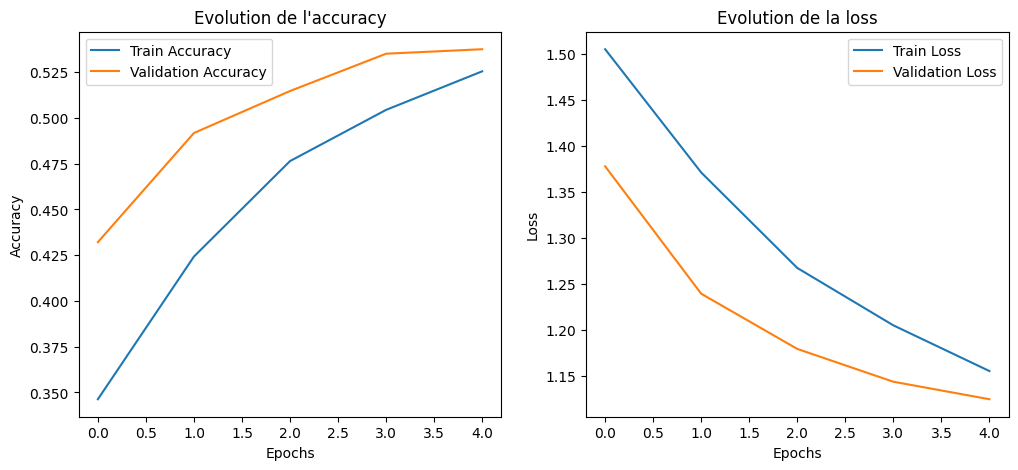

In [ ]:
import matplotlib.pyplot as plt

# Évaluer le modèle sur le dataset de validation
val_loss, val_accuracy = model.evaluate(val_ds)
print(f"Loss sur le dataset de validation : {val_loss:.4f}")
print(f"Accuracy sur le dataset de validation : {val_accuracy:.4f}")

# Visualiser l'évolution de l'accuracy et de la loss pendant l'entraînement
plt.figure(figsize=(12,5)) 

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Evolution de l\'accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Evolution de la loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


## Prédictions

In [8]:
import numpy as np
from tensorflow.keras.preprocessing import image
import os

# Choisir le dossier d'une classe à tester
test_folder = "Data/happy"  # change la classe si tu veux

# Lister toutes les images dans le dossier
all_images = os.listdir(test_folder)
if len(all_images) == 0:
    raise Exception(f"Le dossier {test_folder} est vide !")

# Prendre la première image disponible
img_path = os.path.join(test_folder, all_images[0])
print("Image utilisée pour la prédiction :", img_path)

# Charger et redimensionner l'image
img = image.load_img(img_path, target_size=(128,128))
img_array = image.img_to_array(img) / 255.0   # normalisation
img_array = np.expand_dims(img_array, axis=0) # ajouter dimension batch

# Prédiction
prediction = model.predict(img_array)
predicted_class = class_names[np.argmax(prediction)]
print("Classe prédite :", predicted_class)


Image utilisée pour la prédiction : Data/happy\05-12-21-happy-people.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step
Classe prédite : Happy


In [9]:
model.save("emotion_model.h5")

## Conclusion

Conclusion du Projet

Nous avons construit un classificateur d’émotions faciales utilisant un modèle CNN avec TensorFlow/Keras.

Le dataset a été prétraité et augmenté pour améliorer la robustesse et réduire l’overfitting.

Le modèle a été entraîné et évalué sur des images de validation, obtenant une accuracy satisfaisante.

Des prédictions individuelles peuvent être effectuées sur de nouvelles images pour reconnaître automatiquement les émotions.

Ce projet peut être étendu avec :

Plus de données et de classes d’émotions.

Des architectures plus profondes ou l’utilisation de modèles pré-entraînés (Transfer Learning).

Une interface graphique ou web pour tester facilement le modèle sur des images réelles.

Ce projet montre comment combiner prétraitement, augmentation, CNN et visualisation des résultats pour créer un modèle de reconnaissance d’émotions efficace.